# Bout segmentation — *dummy* body-axis version (baseline / diagnostic)

This is a deliberately **simplified, raw** variant of the bout pipeline, built to show *why the main pipeline does **not** use the tracked body axis for heading*.

**Key differences from the main `segment_bouts.ipynb`:**
- **Heading = the tracked body orientation `f_ori`**, taken **directly at the bout onset** (no displacement, no peak anchor). `f_ori` is a real feature already in the data (radians, CCW, 0 = right) — the tracker provides it; we do not infer it.
- **No Gaussian trajectory smoothing** and no flip-correction — everything is raw.
- Bout *detection* (speed peaks), the per-dish mm scale, the displacement gate, and the gap-only split are otherwise the same.

Output goes to a **separate** file (`bouts_GsizeMotionSingle_bodyaxis.csv`) so the main dataset is untouched.

> **What we actually see (two artefacts, both instructive):**
> 1. **Head/tail flips** — the δθ histogram is peaked at 0 but has clear **lobes at ±180°** (physically impossible reorientations), and the arrow plot shows many bouts whose body axis points *against* the path.
> 2. **Over-detection from no smoothing** — raw speed is spiky, so detection finds ~**110k** bouts vs ~71k in the main pipeline. Many are spurious, closely-spaced detections whose orientation barely changes ($\delta\theta\approx0$), which *inflates* the naive forward fraction.
>
> So a single summary number (forward fraction) can look *better* here while the heading is actually *worse* — exactly why we rely on the **plots** and use displacement-derived, peak-anchored heading in the main pipeline.

## 1. Imports, constants, data

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ---- constants (same detection thresholds as the main pipeline) ----
FPS = 30.0
DISH_RADIUS_MM = 50.0
BOUT_LEAD_FR = round(0.08 * FPS)   # bout start = 80 ms before peak (=2 frames)
REFRACTORY_FR = round(0.40 * FPS)  # min frames between bouts (=12)
DISP_WIN_FR = round(0.50 * FPS)    # +/- displacement window (=15)
DISP_MIN_MM, DISP_MAX_MM = 0.3, 18.0
FORWARD_THRESH_DEG = 10.0
STIM_NONE = {"none", "inter_stim_pause", "bout", "None", None}
# NOTE: no POS_SMOOTH_SIGMA, no speed smoothing -- this dummy version is raw.

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
INPUT_DIR = ROOT / "data" / "data" / "df_transformed"
ROI_PATH = ROOT / "data" / "data" / "ROIdef.csv"
OUT_CSV = ROOT / "data" / "bouts_GsizeMotionSingle_bodyaxis.csv"
csvs = sorted(INPUT_DIR.glob("*_transformed_abs.csv"))
roi = pd.read_csv(ROI_PATH, header=None,
                  names=["xoff", "yoff", "diameter", "x", "y", "radius"])
scale_by_fish = (DISH_RADIUS_MM / roi["radius"]).to_dict()
print(f"{len(csvs)} fish files")

15 fish files


## 2. The body-orientation feature is already in the data

`f{N}_ori` is provided per frame by the tracker (transformed to CCW, 0 = right). We will use it **directly** as the heading — no inference, no smoothing.

In [2]:
df0 = pd.read_csv(csvs[0])
prefix0 = next(re.match(r"(f\d+)_x$", c).group(1) for c in df0.columns if re.match(r"(f\d+)_x$", c))
display(df0[["frame", "stimulus", f"{prefix0}_x", f"{prefix0}_y", f"{prefix0}_ori"]].head())
s = df0[f"{prefix0}_ori"]
print(f"{prefix0}_ori: min={np.nanmin(s):.2f} max={np.nanmax(s):.2f} rad  (0..2pi, CCW, already in the data)")

,frame,stimulus,f0_x,f0_y,f0_ori
0,0,inter_stim_pause,NaN,NaN,NaN
1,1,inter_stim_pause,NaN,NaN,NaN
2,2,inter_stim_pause,NaN,NaN,NaN
3,3,inter_stim_pause,NaN,NaN,NaN
4,4,inter_stim_pause,NaN,NaN,NaN


f0_ori: min=0.00 max=6.28 rad  (0..2pi, CCW, already in the data)


## 3. Helpers (raw — no smoothing)

In [3]:
def wrap_pi(a):
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def parse_stimulus(name):
    out = dict(n_dots_left=np.nan, n_dots_right=np.nan,
               speed_left=np.nan, speed_right=np.nan, side="none", moving=False)
    if not isinstance(name, str) or not name.startswith("CLsemi"):
        return out
    mg = re.search(r"_g(\d+)-(\d+)", name)
    ms = re.search(r"_s([\d.]+)-([\d.]+)", name)
    if mg:
        L, R = int(mg.group(1)), int(mg.group(2))
        out["n_dots_left"], out["n_dots_right"] = L, R
        out["side"] = ("left" if L > 0 and R == 0 else
                       "right" if R > 0 and L == 0 else
                       "both" if L > 0 and R > 0 else "none")
    if ms:
        out["speed_left"], out["speed_right"] = float(ms.group(1)), float(ms.group(2))
        out["moving"] = (out["speed_left"] > 0) or (out["speed_right"] > 0)
    return out


def stim_angle_at(row, fx, fy, f_ori, n_stimuli=8):
    xs, ys = [], []
    for k in range(n_stimuli):
        sc, xc, yc = f"d{k}_stim", f"d{k}_x", f"d{k}_y"
        if sc not in row or row[sc] in STIM_NONE or pd.isna(row.get(xc)):
            continue
        xs.append(row[xc]); ys.append(row[yc])
    if not xs:
        return np.nan
    return float(wrap_pi(np.arctan2(np.mean(ys) - fy, np.mean(xs) - fx) - f_ori))


def fish_xy_mm_raw(seg, prefix, scale):
    """Per-dish-scaled position in mm -- NO smoothing."""
    return (seg[f"{prefix}_x"].to_numpy(dtype=float) * scale,
            seg[f"{prefix}_y"].to_numpy(dtype=float) * scale)


def speed_raw(x, y):
    """Instantaneous speed (mm/s) -- NO smoothing."""
    return np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS


def detect_bouts_raw(x, y, speed_thresh_k):
    """Same speed-peak detection as the main pipeline, but on RAW (unsmoothed)
    speed. Returns aligned (onsets, peaks); onset = peak - 80 ms (bout start)."""
    n = len(x)
    if n < 2 * DISP_WIN_FR + 2:
        return np.array([], dtype=int), np.array([], dtype=int)
    v = speed_raw(x, y)
    thr = np.nanmean(v) + speed_thresh_k * np.nanstd(v)
    peaks, _ = find_peaks(v, height=thr, distance=REFRACTORY_FR)
    onsets = np.clip(peaks - BOUT_LEAD_FR, 0, n - 1)
    keep = []
    for o, p in zip(onsets, peaks):
        a, b = max(o - DISP_WIN_FR, 0), min(o + DISP_WIN_FR, n - 1)
        if DISP_MIN_MM <= np.hypot(x[b] - x[a], y[b] - y[a]) <= DISP_MAX_MM:
            keep.append((o, p))
    if not keep:
        return np.array([], dtype=int), np.array([], dtype=int)
    keep.sort()
    on = np.array([k[0] for k in keep]); pk = np.array([k[1] for k in keep])
    _, idx = np.unique(on, return_index=True)
    return on[idx], pk[idx]


print("helpers defined (raw, no smoothing).")

helpers defined (raw, no smoothing).


## 4. One stimulus block — speed trace and detected bouts

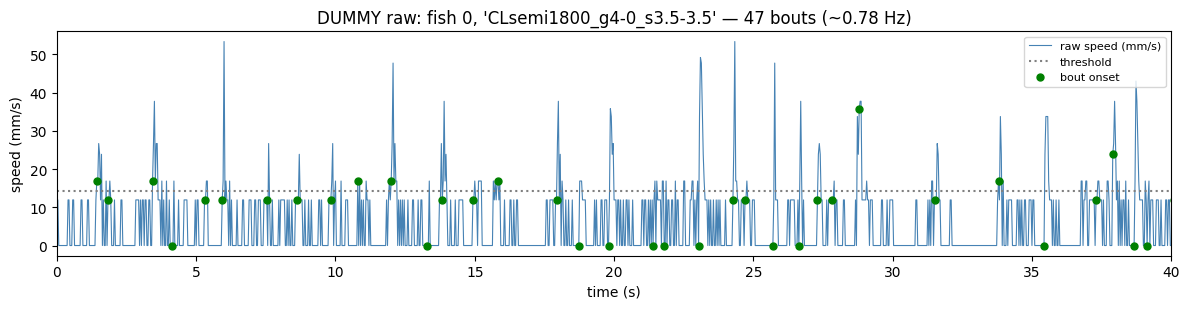

In [4]:
K = 1.0
scale0 = scale_by_fish[0]
blk = (df0["stimulus"] != df0["stimulus"].shift()).cumsum()
cand = df0.assign(_b=blk).groupby("_b").filter(
    lambda g: g["stimulus"].iloc[0].startswith("CLsemi") and len(g) > 600)
seg = cand[cand["_b"] == cand["_b"].iloc[0]].reset_index(drop=True)

x, y = fish_xy_mm_raw(seg, prefix0, scale0)
v = speed_raw(x, y)
onsets, peaks = detect_bouts_raw(x, y, K)
ori = seg[f"{prefix0}_ori"].to_numpy(dtype=float)
t = np.arange(len(v)) / FPS

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, v, lw=0.8, color="steelblue", label="raw speed (mm/s)")
ax.axhline(np.nanmean(v) + K * np.nanstd(v), color="gray", ls=":", label="threshold")
ax.plot(onsets / FPS, v[onsets], "o", color="green", ms=5, label="bout onset")
ax.set_xlim(0, min(40, t[-1])); ax.set_xlabel("time (s)"); ax.set_ylabel("speed (mm/s)")
ax.set_title(f"DUMMY raw: fish 0, '{seg['stimulus'].iloc[0]}' — {len(onsets)} bouts "
             f"(~{len(onsets)/(len(seg)/FPS):.2f} Hz)")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 5. Trajectory coloured by bout order

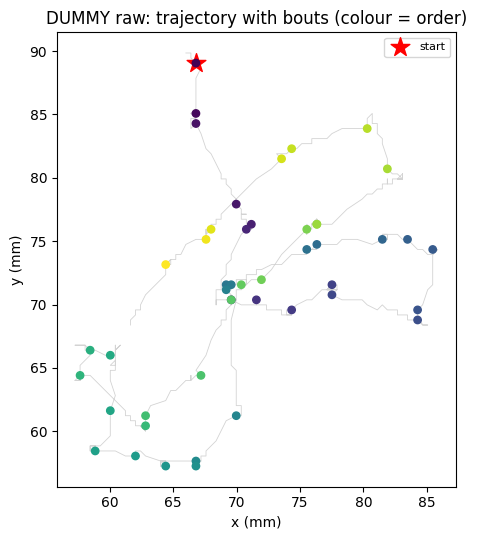

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(x, y, lw=0.6, color="lightgray", zorder=1)
ax.scatter(x[onsets], y[onsets], c=np.arange(len(onsets)), cmap="viridis", s=28, zorder=2)
ax.scatter([x[onsets[0]]], [y[onsets[0]]], marker="*", s=200, color="red", label="start")
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_title("DUMMY raw: trajectory with bouts (colour = order)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Heading arrows = **tracked body axis** `f_ori`, coloured by speed

This is the crucial plot. Each arrow is the **body orientation at the bout onset** (taken straight from the data), coloured by bout speed. If the body axis were reliable, arrows would follow the path. **Watch for arrows pointing backwards / against the path** — those are 180° head/tail flips.

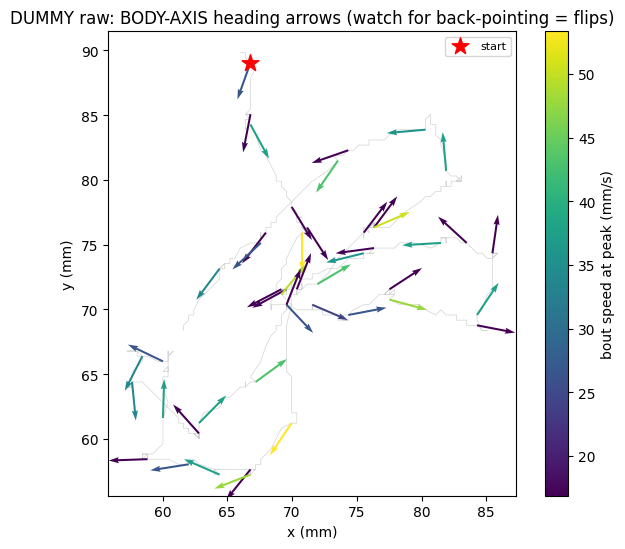

In [6]:
theta = ori[onsets]               # body orientation at bout start (raw, CCW, 0 = right)
bout_speed = v[peaks]             # raw peak speed
ax0, ay0 = x[onsets], y[onsets]

L = 3.0  # arrow length (mm)
fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.plot(x, y, lw=0.5, color="lightgray", zorder=1)
q = ax.quiver(ax0, ay0, L * np.cos(theta), L * np.sin(theta), bout_speed,
              angles="xy", scale_units="xy", scale=1, cmap="viridis",
              width=0.005, zorder=2)
ax.scatter([ax0[0]], [ay0[0]], marker="*", s=160, color="red", zorder=3, label="start")
fig.colorbar(q, ax=ax, label="bout speed at peak (mm/s)")
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_title("DUMMY raw: BODY-AXIS heading arrows (watch for back-pointing = flips)")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 7. Segment all 15 fish (body-axis heading)

In [7]:
def segment_fish_bodyaxis(df, prefix, fish_id, scale, speed_thresh_k):
    """Dummy: heading = raw body orientation at bout onset. No smoothing."""
    df = df.reset_index(drop=True).copy()
    has_pos = df[f"{prefix}_x"].notna() & df[f"{prefix}_y"].notna()
    edges = (~has_pos) & has_pos.shift(fill_value=False)   # split only at gaps
    df["_seg"] = edges.cumsum()

    records = []
    for sid, seg in df.groupby("_seg", sort=True):
        seg = seg[has_pos.loc[seg.index]].reset_index(drop=True)
        if len(seg) < 2 * DISP_WIN_FR + 2:
            continue
        x, y = fish_xy_mm_raw(seg, prefix, scale)
        onsets, peaks = detect_bouts_raw(x, y, speed_thresh_k)
        if len(onsets) < 3:
            continue
        frames = seg["frame"].to_numpy()
        ori = seg[f"{prefix}_ori"].to_numpy(dtype=float)
        theta = ori[onsets]                               # body orientation at onset
        dist = np.hypot(np.diff(x[onsets]), np.diff(y[onsets]))   # onset-to-onset
        dt = np.diff(frames[onsets]) / FPS

        for i in range(1, len(onsets) - 1):
            o = onsets[i]; row = seg.iloc[o]; f_ori = float(theta[i])
            dtheta = wrap_pi(theta[i] - theta[i - 1])      # body-axis reorientation
            stim = row["stimulus"]; ctx = parse_stimulus(stim)
            rec = dict(
                fish_id=fish_id, segment_id=int(sid), bout_index=i,
                frame_onset=int(row["frame"]), t_onset_s=float(row["frame"]) / FPS,
                dtheta_rad=float(dtheta), dtheta_deg=float(np.degrees(dtheta)),
                dt_s=float(dt[i]), distance_mm=float(dist[i]),
                heading_rad=f_ori, f_ori_rad=f_ori,
                x_mm=float(x[o]), y_mm=float(y[o]), stimulus=stim,
                stim_angle_rad=stim_angle_at(row, x[o] / scale, y[o] / scale, f_ori),
                **ctx,
            )
            adeg = abs(rec["dtheta_deg"])
            rec["bout_type"] = ("forward" if adeg < FORWARD_THRESH_DEG
                                else ("left" if dtheta > 0 else "right"))
            records.append(rec)
    return records


all_records = []
for path in csvs:
    fid = int(re.search(r"_f(\d+)_transformed_abs", path.name).group(1))
    dfi = pd.read_csv(path)
    pref = next(re.match(r"(f\d+)_x$", c).group(1) for c in dfi.columns if re.match(r"(f\d+)_x$", c))
    all_records += segment_fish_bodyaxis(dfi, pref, fid, scale_by_fish[fid], K)
bouts = pd.DataFrame(all_records)
print("total bouts:", len(bouts))
bouts.head()

total bouts: 111878


,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dt_s,distance_mm,heading_rad,...,y_mm,stimulus,stim_angle_rad,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type
0,0,0,1,255,8.500000,-2.494,-142.895674,0.666667,8.755457,0.864185,...,75.934881,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
1,0,0,2,275,9.166667,-0.023,-1.317803,0.400000,0.562242,0.841185,...,82.693483,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
2,0,0,3,287,9.566667,-0.007,-0.401070,0.766667,0.888982,0.834185,...,83.091047,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
3,0,0,4,310,10.333333,0.662,37.929806,2.733333,6.863033,1.496185,...,83.886177,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,left
4,0,0,5,392,13.066667,-0.079,-4.526367,1.266667,4.444910,1.417185,...,90.644779,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward


## 8. Reorientation distribution — the flip signature

median |dtheta|   : 22.1 deg
forward (<10 deg) : 0.32
signed dtheta mean: -0.33 deg
bout-type fractions: {'right': 0.339, 'left': 0.338, 'forward': 0.323}


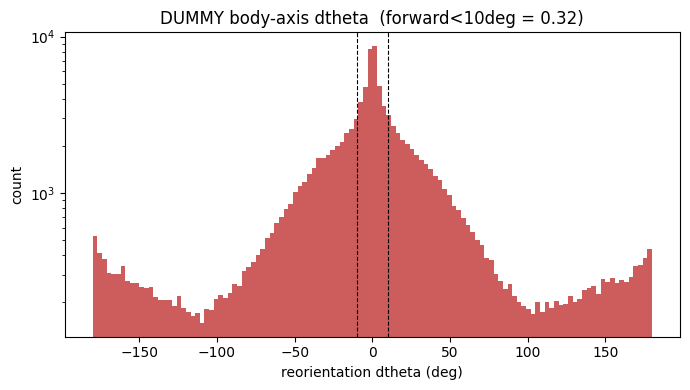

In [8]:
a = bouts["dtheta_deg"].abs()
print(f"median |dtheta|   : {a.median():.1f} deg")
print(f"forward (<10 deg) : {(a < 10).mean():.2f}")
print(f"signed dtheta mean: {bouts['dtheta_deg'].mean():.2f} deg")
print("bout-type fractions:", bouts["bout_type"].value_counts(normalize=True).round(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bouts["dtheta_deg"].clip(-180, 180), bins=120, color="indianred")
ax.axvline(10, color="k", ls="--", lw=0.8); ax.axvline(-10, color="k", ls="--", lw=0.8)
ax.set_yscale("log"); ax.set_xlabel("reorientation dtheta (deg)"); ax.set_ylabel("count")
ax.set_title(f"DUMMY body-axis dtheta  (forward<10deg = {(a < 10).mean():.2f})")
plt.tight_layout(); plt.show()

In [9]:
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
bouts.to_csv(OUT_CSV, index=False)
print(f"saved {len(bouts)} bouts -> {OUT_CSV}")

# quick side-by-side with the main (displacement, peak-anchored) dataset if present
main = OUT_CSV.with_name("bouts_GsizeMotionSingle.csv")
if main.exists():
    m = pd.read_csv(main)
    print("\n               median|dtheta|   forward<10deg")
    print(f"  body-axis (dummy)   {bouts['dtheta_deg'].abs().median():5.1f}        {(bouts['dtheta_deg'].abs()<10).mean():.2f}")
    print(f"  main (displacement) {m['dtheta_deg'].abs().median():5.1f}        {(m['dtheta_deg'].abs()<10).mean():.2f}")

saved 111878 bouts -> c:\Users\arthu\mp_semiCL_behavior\data\bouts_GsizeMotionSingle_bodyaxis.csv

               median|dtheta|   forward<10deg
  body-axis (dummy)    22.1        0.32
  main (displacement)  38.8        0.11


## 9. Conclusion

- A tracked body-orientation feature **does exist** (`f_ori`) and *can* be used directly — this notebook does exactly that, raw and unsmoothed. So the answer to "is there a body-orientation feature?" is **yes**.
- **Flip signature:** the δθ histogram is peaked at 0 but carries clear **lobes at ±180°** — a fish cannot truly reverse direction between bouts; these are **head/tail flips** of the tracked axis. The arrow plot confirms it: many body-axis arrows point *against* the (jagged, unsmoothed) path.
- **A cautionary metric:** the dummy's forward fraction (**0.32**) is actually *higher* than the main pipeline's (**0.22**) — but this is misleading. Removing smoothing **over-detects** bouts (**111,878** vs **70,771**); the extra spurious, closely-spaced detections have $\delta\theta\approx0$ and pad the forward bin. The heading is worse even though the headline number looks better.
- **Takeaways:**
  - the body axis is *available* but *unreliable* here (flips) → we keep it only as a cross-check (`dtheta_ori`), not as the primary heading;
  - smoothing matters for *detection* (it controls over-counting);
  - the main pipeline therefore uses **displacement-derived, peak-anchored** heading and **Gaussian-smoothed** positions.